# Your first simulation

In this tutorial, we solve the Allen-Cahn equation, a standard model of how the boundary between two phases of a material moves, and compare the result with the exact answer. The problem is [PFHub benchmark 7](https://pages.nist.gov/pfhub/benchmarks/benchmark7.ipynb/), which adds a source term chosen so that the exact solution is known. This construction, called a manufactured solution, measures how accurate a simulation code is. We declare the model with the [Recipe API](../overview/modeling/recipe-api.md) and integrate it in time with [`pdesolve`](../overview/simulation/running-a-simulation.md), the two steps of every simulation in diff-soup.

## Setup

We import diff-soup and turn on JAX's 64-bit (double-precision) mode. The grid sizes are set once, in this cell, from the available device, so the same notebook runs on a CPU and a GPU.

In [1]:
import time

import diff_soup as ds
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from diff_soup.domains import cartesian_grid_2d

jax.config.update("jax_enable_x64", True)
GPU = jax.default_backend() == "gpu"
N = 128                                               # cells along y, twice as many along x
SIZES = (32, 64, 128, 256) if GPU else (32, 64, 128)  # grids for the convergence study
print(f"diff-soup {ds.__version__}, JAX {jax.__version__}, {jax.devices()[0].platform}")

diff-soup 1.1.0, JAX 0.11.2, gpu


## The problem

We consider an order parameter $\eta(x, y, t)$, a number that is 1 in one phase and 0 in the other, which evolves under the Allen-Cahn equation with a source term,

$$
\frac{\partial \eta}{\partial t} = \kappa \nabla^2 \eta - 4\eta(\eta - 1)\left(\eta - \tfrac{1}{2}\right) + S(x, y, t),
$$

where $\kappa = 4 \times 10^{-4}$ is the gradient energy coefficient, which sets the width of the boundary, the cubic term pulls $\eta$ towards 0 or 1, and $S$ is the source. The domain is the rectangle $0 \le x \le 1$, $0 \le y \le 0.5$, and we integrate from $t = 0$ to $t = 8$, all in dimensionless units.

The benchmark chooses $S$ so that the exact solution $\eta^*$ is a smooth boundary, or diffuse interface, of width $\sqrt{2\kappa}$ that follows the curve $y = \alpha(x, t)$,

$$
\eta^*(x, y, t) = \frac{1}{2}\left[1 - \tanh\frac{y - \alpha(x, t)}{\sqrt{2\kappa}}\right], \qquad
\alpha(x, t) = \frac{1}{4} + A_1 t \sin(B_1 x) + A_2 \sin(B_2 x + C_2 t),
$$

with $A_1 = 0.0075$, $B_1 = 8\pi$, $A_2 = 0.03$, $B_2 = 22\pi$ and $C_2 = 0.0625\pi$. The initial condition is $\eta^*$ at $t = 0$, so any later difference from $\eta^*$ is numerical error. We write $\alpha$, $\eta^*$ and $S$ as JAX functions, taking the lengthy formula for $S$ from the benchmark statement.

In [2]:
kappa, A1, B1, A2, B2, C2 = 4e-4, 0.0075, 8 * np.pi, 0.03, 22 * np.pi, 0.0625 * np.pi
w = np.sqrt(2 * kappa)                                # interface width

def alpha(x, t):
    return 0.25 + A1 * t * jnp.sin(B1 * x) + A2 * jnp.sin(B2 * x + C2 * t)

def eta_exact(x, y, t):
    return 0.5 * (1 - jnp.tanh((y - alpha(x, t)) / w))

def source(x, y, t):
    a_x = A1 * B1 * t * jnp.cos(B1 * x) + A2 * B2 * jnp.cos(B2 * x + C2 * t)
    a_xx = -A1 * B1**2 * t * jnp.sin(B1 * x) - A2 * B2**2 * jnp.sin(B2 * x + C2 * t)
    a_t = A1 * jnp.sin(B1 * x) + A2 * C2 * jnp.cos(B2 * x + C2 * t)
    z = (y - alpha(x, t)) / w
    bracket = -2 * np.sqrt(kappa) * jnp.tanh(z) * a_x**2 + np.sqrt(2) * (a_t - kappa * a_xx)
    return bracket / (4 * np.sqrt(kappa) * jnp.cosh(z) ** 2)

## Build the model

A model in diff-soup is declared as a recipe. First, we open one with `ds.problem`, register a grid of $2N \times N$ finite-volume cells as its domain, and declare $\eta$ as a field on it. The solver then tracks the average of $\eta$ in each cell. The field is `"differential"` because it carries a time derivative, and `init` gives its starting value.

In [3]:
grid = cartesian_grid_2d(2 * N, N, 1.0, 0.5)
spec = ds.problem("allen_cahn")
spec.domain("plate", grid)
spec.field("eta", mass="differential", scale=1.0, init=lambda x, y: eta_exact(x, y, 0.0))
grid.shape

(256, 128)

Next, we write the equation as a Python function of the access object `q` that returns $\partial \eta / \partial t$. Inside it, `q.eta` is the current state, `q.ops.laplacian` applies the discrete Laplacian, and `q.x` and `q.t` are the cell centres and the time.

In [4]:
@spec.equation(writes="eta", reads=("eta",))
def allen_cahn(q):
    x, y = q.x[:, 0], q.x[:, 1]
    bulk = 4 * q.eta * (q.eta - 1) * (q.eta - 0.5)
    return kappa * q.ops.laplacian(q.eta) - bulk + source(x, y, q.t)

The benchmark is periodic in $x$, meaning that the left and right edges wrap around and meet, so `spec.bc.periodic` wraps the first axis alone. On the walls at $y = 0$ and $y = 0.5$, we pin $\eta$ to the exact solution at the adjacent cell centres with `spec.bc.dirichlet`. Those centres come from `grid.meshgrid()`, which returns arrays of shape `grid.shape`, so `X[:, 0]` is the bottom row of cells.

In [5]:
X, Y = grid.meshgrid()                                # cell centres, shape (2N, N)
h = 1.0 / (2 * N)                                     # cell width
spec.bc.periodic("eta", axes=(0,))
spec.bc.dirichlet("eta", axis=1, side="low", value_fn=lambda t: eta_exact(X[:, 0], Y[:, 0], t))
spec.bc.dirichlet("eta", axis=1, side="high", value_fn=lambda t: eta_exact(X[:, -1], Y[:, -1], t))

Finally, `spec.build` turns the recipe into a problem the solvers accept, and `spec.assemble_state` returns the initial state as a vector with one entry per cell.

In [6]:
problem = spec.build()
y0 = spec.assemble_state({})
y0.shape

(32768,)

## Solve

We integrate from $t = 0$ to $t = 8$ with `ds.pdesolve` and `ds.JIDA`, the recommended solver, which adapts both the size of its time steps and the order of its formula. The call returns a `Solution` that holds the saved states and the solver statistics.

In [7]:
solver = ds.JIDA()
sol = ds.pdesolve(problem, solver, (0.0, 8.0), y0)
print("reached t = 8:", bool(sol.ok))
print(f"{int(sol.stats.accepts)} steps, {int(sol.stats.newton_iters)} Newton iterations")

reached t = 8: True
82 steps, 113 Newton iterations


By default only the final state is saved, as `sol.ys[-1]`, and we plot it with the exact interface $\alpha(x, 8)$ dashed on top.

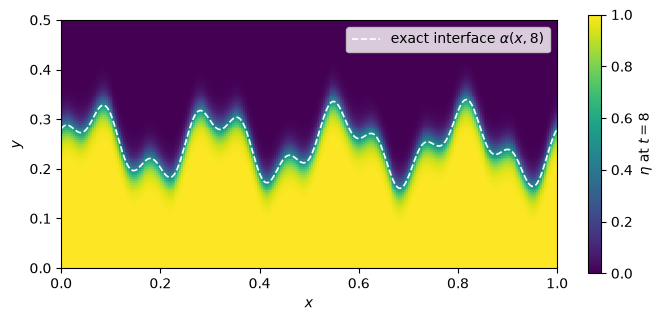

In [8]:
eta = np.asarray(sol.ys[-1]).reshape(grid.shape)
xs = np.linspace(0, 1, 400)
fig, ax = plt.subplots(figsize=(8, 4.2))
im = ax.pcolormesh(X, Y, eta, cmap="viridis", shading="nearest")
ax.plot(xs, alpha(xs, 8.0), "w--", lw=1.2, label=r"exact interface $\alpha(x, 8)$")
ax.set(xlabel="$x$", ylabel="$y$", aspect="equal")
ax.legend(loc="upper right")
fig.colorbar(im, ax=ax, label=r"$\eta$ at $t = 8$", shrink=0.8)
plt.show()

## Check

The computed interface, where $\eta$ crosses one half, lies on the exact curve. To put a number on the agreement, we use the benchmark's error measure, the discrete $L_2$ norm of the difference from the exact solution at $t = 8$,

$$
L_2 = \Big(\sum (\eta - \eta^*)^2 \, \Delta x \, \Delta y\Big)^{1/2}.
$$

In [9]:
def l2_error(sol, X, Y, h):
    return float(jnp.sqrt(jnp.sum((sol.ys[-1] - eta_exact(X, Y, 8.0).ravel()) ** 2) * h * h))

print(f"L2 error on the {2 * N} x {N} grid: {l2_error(sol, X, Y, h):.2e}")

L2 error on the 256 x 128 grid: 8.34e-04


The error of $8.3 \times 10^{-4}$ is small next to the jump of 1 across the interface. To see whether it falls at the rate the discretization promises, we need more than one grid.

## Grid refinement

Next, we measure the order of convergence, the rate at which the error falls as the cells shrink. We wrap the recipe in a function of the grid size and solve on finer and finer grids. The function registers the equation written above with `spec.equation(...)(allen_cahn)`, and since each new grid size compiles a fresh solve, most of the printed times include compilation.

In [10]:
def solve_on_grid(n, solver=ds.JIDA()):
    grid = cartesian_grid_2d(2 * n, n, 1.0, 0.5)
    X, Y = grid.meshgrid()
    spec = ds.problem("allen_cahn")
    spec.domain("plate", grid)
    spec.field("eta", mass="differential", scale=1.0, init=lambda x, y: eta_exact(x, y, 0.0))
    spec.equation(writes="eta", reads=("eta",))(allen_cahn)
    spec.bc.periodic("eta", axes=(0,))
    spec.bc.dirichlet("eta", axis=1, side="low", value_fn=lambda t: eta_exact(X[:, 0], Y[:, 0], t))
    spec.bc.dirichlet("eta", axis=1, side="high", value_fn=lambda t: eta_exact(X[:, -1], Y[:, -1], t))
    sol = ds.pdesolve(spec.build(), solver, (0.0, 8.0), spec.assemble_state({}))
    h = 1.0 / (2 * n)
    return h, l2_error(sol, X, Y, h)

  64 x 32   L2 = 2.35e-02   (4.0 s)


 128 x 64   L2 = 3.66e-03   (3.9 s)


 256 x 128  L2 = 8.34e-04   (1.7 s)


 512 x 256  L2 = 2.05e-04   (5.6 s)
observed order: 2.08


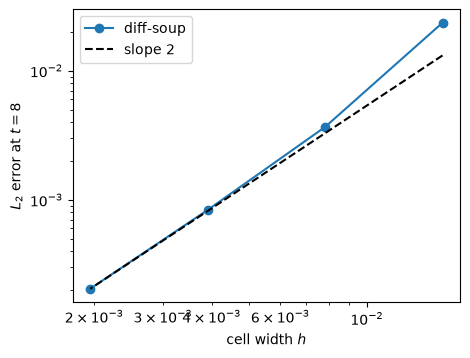

In [11]:
hs, errors = [], []
for n in SIZES:
    start = time.perf_counter()
    h_n, e_n = solve_on_grid(n)
    hs.append(h_n), errors.append(e_n)
    print(f"{2 * n:4d} x {n:<4d} L2 = {e_n:.2e}   ({time.perf_counter() - start:.1f} s)")
order = np.polyfit(np.log(hs[1:]), np.log(errors[1:]), 1)[0]
print(f"observed order: {order:.2f}")

fig, ax = plt.subplots(figsize=(5, 3.8))
ax.loglog(hs, errors, "o-", label="diff-soup")
ax.loglog(hs, errors[-1] * (np.array(hs) / hs[-1]) ** 2, "k--", label="slope 2")
ax.set(xlabel="cell width $h$", ylabel="$L_2$ error at $t = 8$")
ax.legend()
plt.show()

On the finer grids the error falls about fourfold with each halving of $h$, an observed order of 2.08, which matches the second-order finite-volume Laplacian. We leave the coarsest grid out of the fit, since it puts fewer than two cells across the interface width $\sqrt{2\kappa}$.

This measures the error of the grid only if the error of the time steps is much smaller. To check, we repeat the finest grid with tolerances, the error each step may make, a hundred times tighter than the default of `1e-6`.

In [12]:
_, e_tight = solve_on_grid(SIZES[-1], ds.JIDA(rtol=1e-8, atol=1e-8))
print(f"default tolerances: L2 = {errors[-1]:.4e}")
print(f"rtol = atol = 1e-8:  L2 = {e_tight:.4e}")

default tolerances: L2 = 2.0488e-04
rtol = atol = 1e-8:  L2 = 2.0492e-04


The two errors agree to three digits, so the time stepping contributes almost nothing and the error we measured is the grid's.